In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
transformLabel = lambda x: x - 1

trainDataset= datasets.EMNIST(root=pathToData,
                              split='letters',
                              train=True,
                              download=True,
                              transform=ToTensor(),
                              target_transform=transformLabel)
testDataset= datasets.EMNIST(root=pathToData,
                             split='letters',
                             train=False,
                             download=True,
                             transform=ToTensor(),
                             target_transform=transformLabel)
trainLoader = torch.utils.data.DataLoader(trainDataset, batch_size=BATCH_SIZE, shuffle=True)
testLoader = torch.utils.data.DataLoader(testDataset, batch_size=BATCH_SIZE, shuffle=False)

In [4]:
len(trainDataset), len(testDataset)

(124800, 20800)

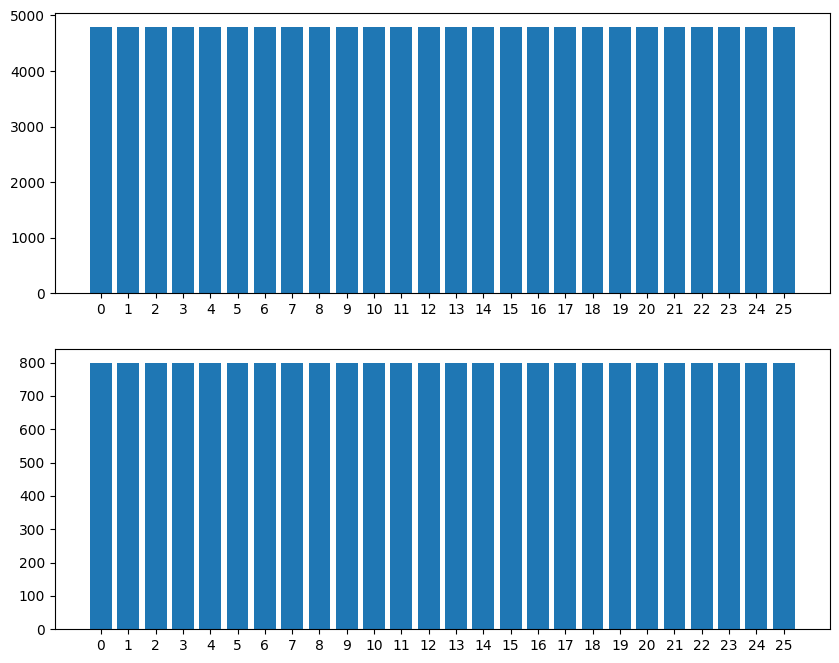

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(10, 8)) 

trainCounts = np.bincount([y for _, y in trainDataset])
axs[0].bar(range(len(trainCounts)), trainCounts)
axs[0].set_xticks(range(len(trainCounts)))

testCounts = np.bincount([y for _, y in testDataset])
axs[1].bar(range(len(testCounts)), testCounts)
axs[1].set_xticks(range(len(testCounts)))

plt.show()

In [6]:
from models.eMnist.model import eMnistModel
from utils import *
import torch.nn as nn
import torch.optim as optim

In [7]:
model = eMnistModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 10, 'eMnist')

Epoch 1/10 - Train Loss: 0.0124, Train Accuracy: 0.7516 - Test Loss: 0.0047, Test Accuracy: 0.9018
Epoch 2/10 - Train Loss: 0.0070, Train Accuracy: 0.8557 - Test Loss: 0.0040, Test Accuracy: 0.9181
Epoch 3/10 - Train Loss: 0.0059, Train Accuracy: 0.8792 - Test Loss: 0.0035, Test Accuracy: 0.9271
Epoch 4/10 - Train Loss: 0.0052, Train Accuracy: 0.8917 - Test Loss: 0.0034, Test Accuracy: 0.9300
Epoch 5/10 - Train Loss: 0.0047, Train Accuracy: 0.9026 - Test Loss: 0.0033, Test Accuracy: 0.9330
Epoch 6/10 - Train Loss: 0.0043, Train Accuracy: 0.9089 - Test Loss: 0.0032, Test Accuracy: 0.9359
Epoch 7/10 - Train Loss: 0.0041, Train Accuracy: 0.9125 - Test Loss: 0.0031, Test Accuracy: 0.9362
Epoch 8/10 - Train Loss: 0.0039, Train Accuracy: 0.9163 - Test Loss: 0.0032, Test Accuracy: 0.9356
Epoch 9/10 - Train Loss: 0.0038, Train Accuracy: 0.9190 - Test Loss: 0.0031, Test Accuracy: 0.9363
Epoch 10/10 - Train Loss: 0.0036, Train Accuracy: 0.9219 - Test Loss: 0.0033, Test Accuracy: 0.9339


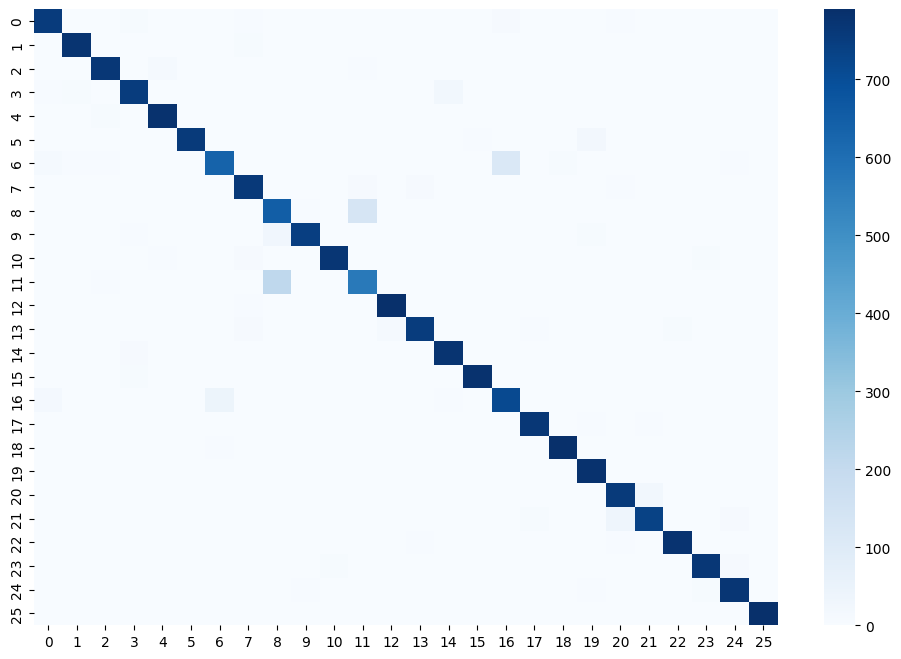

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for images, labels in testLoader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap='Blues')
    
plt.show()